# City-wide validation of mean velocities

Compares the mean velocities (2022-01-01 – 2024-12-31) of four InSAR point datasets over the whole project AOI:

| Dataset | Role | Velocity column |
|---|---|---|
| **Augmenterra** | reference | `VEL_20220101_20241231` |
| **EGMS** | reference | `VEL_20220101_20241231` |
| **COMPASS-Dolphin** | own COMPASS-Dolphin processing | `velocity_dolphin` |
| **ISCE2-Dolphin-MintPy** | own ISCE2-Dolphin-MintPy processing (`S1_ASC_073_IW1-IW2_VV_20220101_20241228_vienna`) | `velocity_mintpy` |

The datasets have different point locations, so points cannot be compared one to one. Instead:
1. Load the points inside the AOI (only coordinates, velocity and coherence).
2. Aggregate all datasets onto the same regular grid (40 m cells, EPSG:31256).
3. Put all datasets on a common reference: subtract each dataset's median velocity over the *commonly stable* cells.
4. Compare the cell velocities pairwise (raw and aligned): metrics table, density scatter plots, difference maps.

**Conventions**: velocities in mm/yr in line of sight (LOS); negative = away from the satellite (e.g. subsidence).
Differences are always **second − first dataset** of a pair. References come first, own processings second, e.g.
`COMPASS-Dolphin − Augmenterra`; the two own processings are compared as `ISCE2-Dolphin-MintPy − COMPASS-Dolphin`
(positive = the second dataset shows higher velocities, i.e. less subsidence).

**Code**: readers, metrics, grid and alignment come from the package `aducat_val` (`src/aducat_val/`).
Conventions (sign, units, CRS, reference): `docs/conventions.md`.

**Efficiency**: points are read one row group at a time with only the needed columns.
Grid cells are computed arithmetically from the coordinates (no polygon grid and no spatial join).

In [1]:
import sys
import time
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap, LogNorm, Normalize
from matplotlib.patches import Patch

try:
    import aducat_val
except ImportError:  # package not installed with `pip install -e .`: use src/ of this repo (see README.md)
    repo_root = next(p for p in Path.cwd().resolve().parents if (p / "src" / "aducat_val").is_dir())
    sys.path.insert(0, str(repo_root / "src"))

from aducat_val import alignment, metrics, readers, spatial
from aducat_val.config import METRIC_CRS, VELOCITY_CMAP
from aducat_val.display import metrics_box, panel_axes, show, style_map

## Configuration

Set the paths at the top of the next cell to where the data is on your machine.
`DATASETS` maps each dataset name to its file and the options of its source function in `aducat_val/readers.py`;
every later cell loops over the datasets.

In [2]:
# ---- Paths: set them to where the data is on your machine ----
DATA_DIR = Path("/home/lukas/projects/ADUCAT/data")
AOI_FILE = DATA_DIR / "AOI/Projektgebiet_ADUCAT-AOI.gpkg"

# name -> file and options of the source function in aducat_val/readers.py (velocity column, ...)
DATASETS = {
    "Augmenterra": dict(file=DATA_DIR / "Augmenterra/processed/VIENNA_TUNNELLING_velocity_ASC.parquet",
                        velocity="VEL_20220101_20241231"),
    "EGMS": dict(file=DATA_DIR / "EGMS/vienna/EGMS_L2A_073_2020_2024.parquet",
                 velocity="VEL_20220101_20241231"),
    "COMPASS-Dolphin": dict(file=DATA_DIR / "final_outputs/COMPASS-DOLPHIN/dolphin_points_2020-2024.parquet"),
    "ISCE2-Dolphin-MintPy": dict(
        file=DATA_DIR / "final_outputs/isce2-dolphin-mintpy/S1_ASC_073_IW1-IW2_VV_20220101_20241228_vienna.parquet"),
}
SOURCES = readers.sources(DATASETS)
# own processings; in a pair they are placed after the references (in this order)
OWN = [name for name, src in SOURCES.items() if src.kind == "pipeline"]

# Coherence threshold per dataset: points with a lower coherence (or no coherence) are dropped right after
# loading and are then missing in all following steps. 0 = keep all points.
# The providers compute coherence differently, so a threshold of one dataset does not mean the same in another.
MIN_COHERENCE = {
    "Augmenterra": 0.0,
    "EGMS": 0.0,
    "COMPASS-Dolphin": 0.8,
    "ISCE2-Dolphin-MintPy": 0.8,      # MintPy coherence, other scale; the file is already filtered at >= 0.7
}

# Grid and comparison settings (grid CRS = METRIC_CRS from aducat_val.config)
GRID_SIZE_M = 40                   # grid cell size
CELL_AGG = "mean"                  # velocity per cell: "mean" or "median" (median is more robust to outliers)
MIN_POINTS_PER_CELL = 1            # cells with fewer points of a dataset are ignored in the comparison

# Common reference on commonly stable cells (section 4)
ALIGN_TO_STABLE = True             # True: compare velocities after subtracting each dataset's offset
STABLE_TOL = 1.0                   # stable: |cell velocity − dataset offset| <= STABLE_TOL mm/yr in EVERY dataset
STABLE_MIN_POINTS = 3              # points per cell each dataset needs for the stable-cell selection

# Plot settings
VEL_LIMIT = 20                     # colour / axis range of velocities: -VEL_LIMIT ... +VEL_LIMIT mm/yr
DIFF_LIMIT = 10                    # colour range of difference maps: -DIFF_LIMIT ... +DIFF_LIMIT mm/yr
CMAP = VELOCITY_CMAP               # red = negative (away from satellite), blue = positive
PLOTS_PER_ROW = 3                  # panels per row in the pairwise plots

## 1. Load the points inside the AOI

The coherence thresholds from `MIN_COHERENCE` are applied here. The second table shows which share of the
points in the AOI would remain at other thresholds, to help choose them.

In [3]:
aoi_polygon, aoi_metric = spatial.read_aoi(AOI_FILE)     # lon/lat polygon for selecting, metric for grid and maps
aoi_area_km2 = aoi_metric.area.sum() / 1e6
print(f"AOI area: {aoi_area_km2:.1f} km²")

AOI area: 484.8 km²


In [4]:
points = {}
loading = {}
threshold_shares = {}

for name, src in SOURCES.items():
    t0 = time.perf_counter()
    pts = readers.read_points(src, aoi_polygon)
    min_coh = MIN_COHERENCE.get(name, 0.0)
    n_aoi_all = len(pts)

    threshold_shares[name] = metrics.coherence_shares(pts["coherence"])
    if min_coh > 0:
        pts = pts[pts["coherence"] >= min_coh].reset_index(drop=True)
    points[name] = pts

    loading[name] = {
        "coherence threshold": min_coh,
        "points in AOI": n_aoi_all,
        "points kept": len(pts),
        "kept [%]": 100 * len(pts) / n_aoi_all if n_aoi_all else np.nan,
        "loading time [s]": time.perf_counter() - t0,
    }

show(pd.DataFrame(loading), decimals=2, int_labels=("points in AOI", "points kept"))
print("Share of points in the AOI [%] at or above a coherence threshold (before filtering):")
show(pd.DataFrame(threshold_shares), decimals=1)

# short description of the thresholds for the figure titles
COH_INFO = "coherence ≥ " + ", ".join(f"{MIN_COHERENCE.get(name, 0.0)} ({name})" for name in points)

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
coherence threshold,0.00,0.00,0.80,0.80
points in AOI,"2,918,003","1,252,938","4,588,399","5,203,546"
points kept,"2,918,003","1,252,938","2,428,525","5,174,065"
kept [%],100.00,100.00,52.93,99.43
loading time [s],1.93,0.85,1.77,1.87


Share of points in the AOI [%] at or above a coherence threshold (before filtering):


,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
≥ 0.3,91.7,99.9,99.9,100.0
≥ 0.5,60.4,99.4,73.7,100.0
≥ 0.6,46.8,95.9,62.6,100.0
≥ 0.7,32.7,79.2,57.6,100.0
≥ 0.8,21.8,56.5,52.9,99.4
≥ 0.9,8.8,19.9,46.3,98.2


## 2. Regular grid over the AOI

`spatial.Grid` covers the AOI bounding box with `GRID_SIZE_M` cells. Each cell has an integer id
`row * nx + column` (row 0 = north), so the cell of a point follows directly from its coordinates
and every per-cell result can be turned back into an image with `grid.to_image`.
A cell belongs to the AOI if its centre lies inside the AOI polygon.

In [5]:
grid = spatial.Grid.over(aoi_metric, GRID_SIZE_M)
print(f"Grid: {grid.nx} x {grid.ny} = {grid.nx * grid.ny:,} cells of {GRID_SIZE_M} m, {grid.n_cells:,} of them inside the AOI")

Grid: 756 x 575 = 434,700 cells of 40 m, 302,828 of them inside the AOI


## 3. Statistics per grid cell

For every dataset and cell: mean, median and standard deviation of the velocity, number of points,
and the median coherence.

In [6]:
cell_stats = {}
assignment = {}

for name, pts in points.items():
    cell_stats[name] = grid.aggregate(pts, mean=("velocity", "mean"), median=("velocity", "median"),
                                      std=("velocity", "std"), count=("velocity", "size"),
                                      coherence=("coherence", "median"))
    assigned = grid.cell_index(pts["x"], pts["y"]) >= 0
    assignment[name] = {"points": len(pts), "assigned to a cell [%]": 100 * assigned.mean()}

show(pd.DataFrame(assignment), decimals=2)

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
points,"2,918,003","1,252,938","2,428,525","5,174,065"
assigned to a cell [%],99.96,99.97,99.96,99.95


### 3.1 Coverage and points per cell

Points per cell statistics refer to occupied cells only.

In [7]:
coverage = {}
for name, stats in cell_stats.items():
    n = stats["count"]
    coverage[name] = {
        "occupied cells": len(stats),
        "AOI cells covered [%]": 100 * len(stats) / grid.n_cells,
        f"cells with ≥ {MIN_POINTS_PER_CELL} points (used)": (n >= MIN_POINTS_PER_CELL).sum(),
        "points per cell: mean": n.mean(),
        "points per cell: median": n.median(),
        "points per cell: max": n.max(),
    }

show(pd.DataFrame(coverage), decimals=1,
     int_labels=("occupied cells", f"cells with ≥ {MIN_POINTS_PER_CELL} points (used)", "points per cell: max"))

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
occupied cells,"208,234","143,219","171,151","195,119"
AOI cells covered [%],68.8,47.3,56.5,64.4
cells with ≥ 1 points (used),"208,234","143,219","171,151","195,119"
points per cell: mean,14.0,8.7,14.2,26.5
points per cell: median,15.0,7.0,16.0,28.0
points per cell: max,88,91,16,60


### 3.2 Maps per dataset

Rows: velocity per cell (`CELL_AGG`), median coherence per cell, number of points per cell.
Coherence is computed differently by each provider, so compare its pattern rather than its values.
The velocities here are the original (raw) values, before the alignment of section 4.

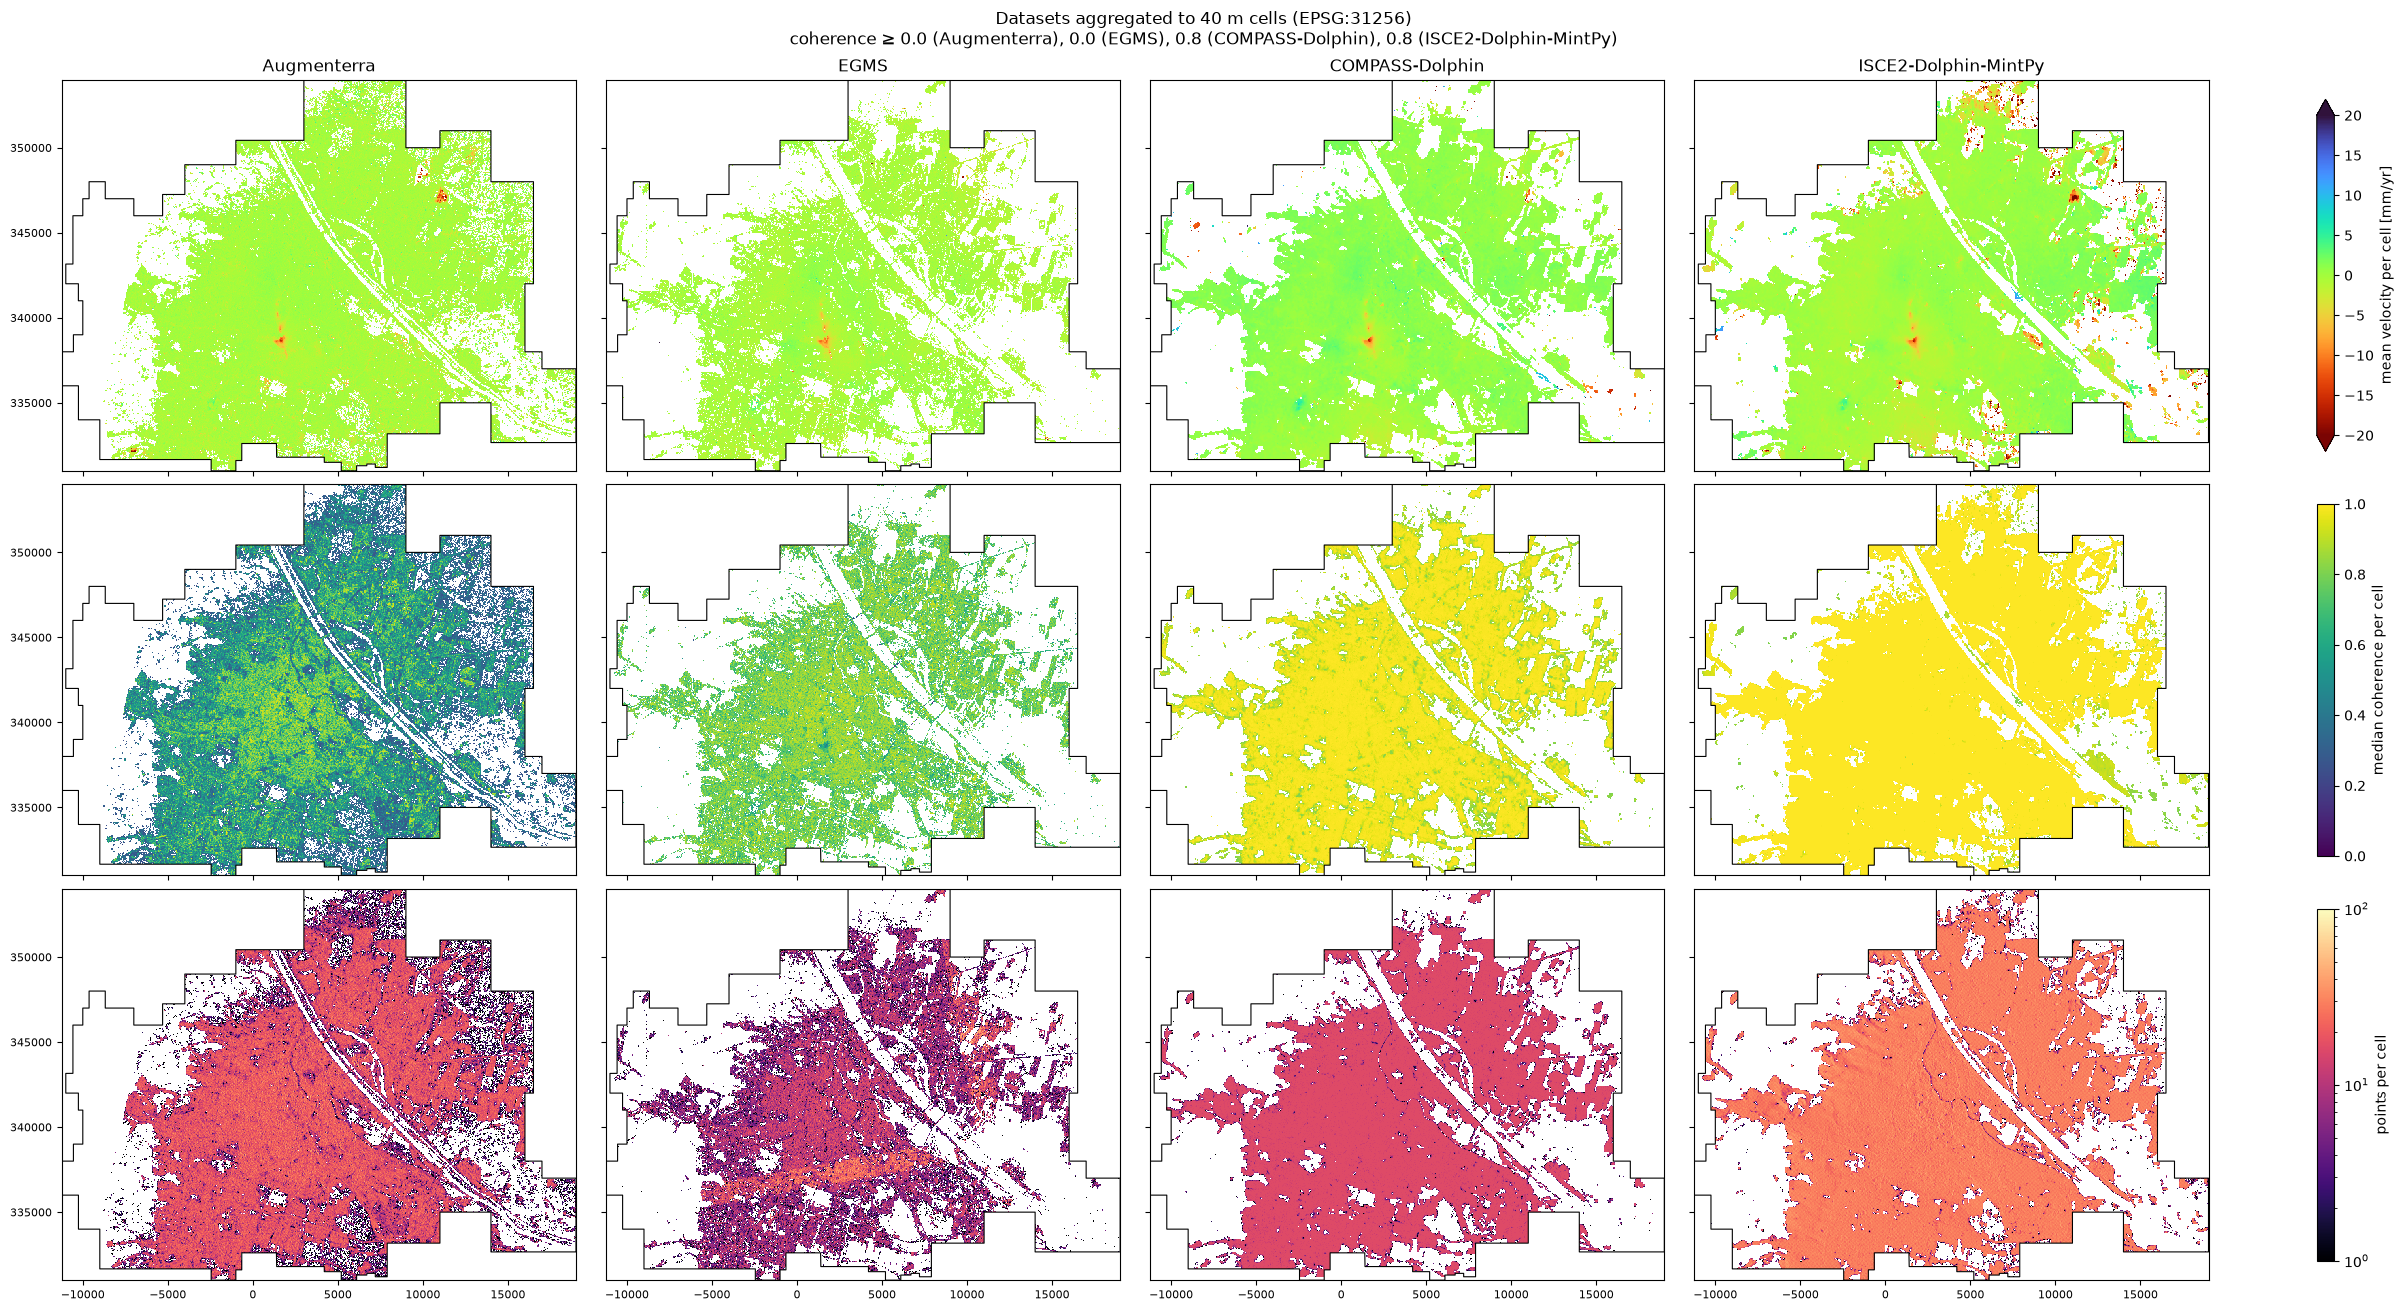

In [8]:
n = len(cell_stats)
fig, axes = plt.subplots(3, n, figsize=(6 * n, 13), sharex=True, sharey=True, constrained_layout=True)
axes = np.atleast_2d(axes.T).T      # keeps 2D indexing when only one dataset is configured

map_rows = [
    # (column, colormap, norm, colour bar label)
    (CELL_AGG, CMAP, Normalize(-VEL_LIMIT, VEL_LIMIT), f"{CELL_AGG} velocity per cell [mm/yr]"),
    ("coherence", "viridis", Normalize(0, 1), "median coherence per cell"),
    ("count", "magma", LogNorm(1, 100), "points per cell"),
]

for col, (name, stats) in enumerate(cell_stats.items()):
    axes[0, col].set_title(name)
    for row, (column, cmap, norm, _) in enumerate(map_rows):
        ax = axes[row, col]
        ax.imshow(grid.to_image(stats[column]), extent=grid.extent, cmap=cmap, norm=norm, interpolation="nearest")
        style_map(ax, aoi_metric)

for row, (_, cmap, norm, label) in enumerate(map_rows):
    fig.colorbar(ScalarMappable(norm, cmap), ax=axes[row], shrink=0.9, label=label,
                 extend="both" if row == 0 else "neither")
fig.suptitle(f"Datasets aggregated to {GRID_SIZE_M} m cells ({METRIC_CRS})\n{COH_INFO}")
plt.show()

## 4. Common reference: alignment on commonly stable cells

InSAR velocities are relative to a reference point or area (EGMS L2a is not calibrated with GNSS either),
so each dataset can be shifted by a constant offset. This offset is estimated and removed as follows.

**Why stable cells cannot simply be |v| < 1 mm/yr**: the offset itself decides which cells pass such a test,
e.g. with an offset of +1.2 mm/yr most truly stable cells of a dataset would fail it. The criterion is therefore
taken relative to each dataset's own offset, which makes it independent of the offset:

1. **Common cells**: cells where *every* dataset has at least `STABLE_MIN_POINTS` points.
2. **Start**: offset of each dataset = its median velocity over all common cells
   (fine as a first guess because most of the city does not move).
3. **Commonly stable cells**: common cells where |velocity − offset| ≤ `STABLE_TOL` in **every** dataset.
   A cell that moves in any dataset is excluded, also if only one dataset sees the motion.
4. **Update**: offset = median velocity over the commonly stable cells only; repeat steps 3–4 until the offsets
   change by less than 0.001 mm/yr.

Implemented in `aducat_val.alignment.stable_offsets`. The aligned velocity is `velocity − offset`, so all datasets have a median of 0 over the same stable cells.
A remaining spatial trend (tilt) between the datasets is **not** removed by this step.

In [9]:
common_cells = alignment.common_values(cell_stats, CELL_AGG, min_count=STABLE_MIN_POINTS)
offsets, stable_cells, iteration = alignment.stable_offsets(common_cells, tol=STABLE_TOL)

print(f"Common cells (all datasets ≥ {STABLE_MIN_POINTS} points): {len(common_cells):,}")
print(f"Commonly stable cells (|v − offset| ≤ {STABLE_TOL} mm/yr in every dataset): "
      f"{len(stable_cells):,} ({100 * len(stable_cells) / len(common_cells):.1f} % of the common cells)")
print(f"Converged after {iteration} iterations")

# offsets that are subtracted in section 5 (zero if the alignment is switched off)
VELOCITY_OFFSET = offsets if ALIGN_TO_STABLE else offsets * 0.0
ALIGN_INFO = (f"aligned on {len(stable_cells):,} commonly stable cells" if ALIGN_TO_STABLE
              else "raw velocities (no alignment)")

Common cells (all datasets ≥ 3 points): 116,300
Commonly stable cells (|v − offset| ≤ 1.0 mm/yr in every dataset): 75,887 (65.3 % of the common cells)
Converged after 4 iterations


Offsets per dataset. *Offset relative to …* is the shift between a dataset and each own processing
that the alignment removes. The NMAD (robust spread) over the stable cells shows how well each dataset agrees with
"no motion" there.

In [10]:
stable = common_cells.loc[stable_cells]
alignment = pd.DataFrame({
    "offset = median over stable cells [mm/yr]": offsets,
    "median over all common cells [mm/yr]": common_cells.median(),
    **{f"offset relative to {own} [mm/yr]": offsets - offsets[own] for own in OWN if own in offsets},
    "NMAD over stable cells [mm/yr]": stable.apply(metrics.nmad),
}).T
show(alignment)

,Augmenterra,EGMS,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
offset = median over stable cells [mm/yr],-0.17,-0.24,0.96,0.13
median over all common cells [mm/yr],-0.21,-0.30,0.93,0.17
offset relative to COMPASS-Dolphin [mm/yr],-1.13,-1.20,0.00,-0.83
offset relative to ISCE2-Dolphin-MintPy [mm/yr],-0.31,-0.37,0.83,0.00
NMAD over stable cells [mm/yr],0.43,0.46,0.44,0.51


Left: location of the common and the commonly stable cells. Right: distribution of the velocities over the
common cells relative to each dataset's offset; the grey band is the stability tolerance.

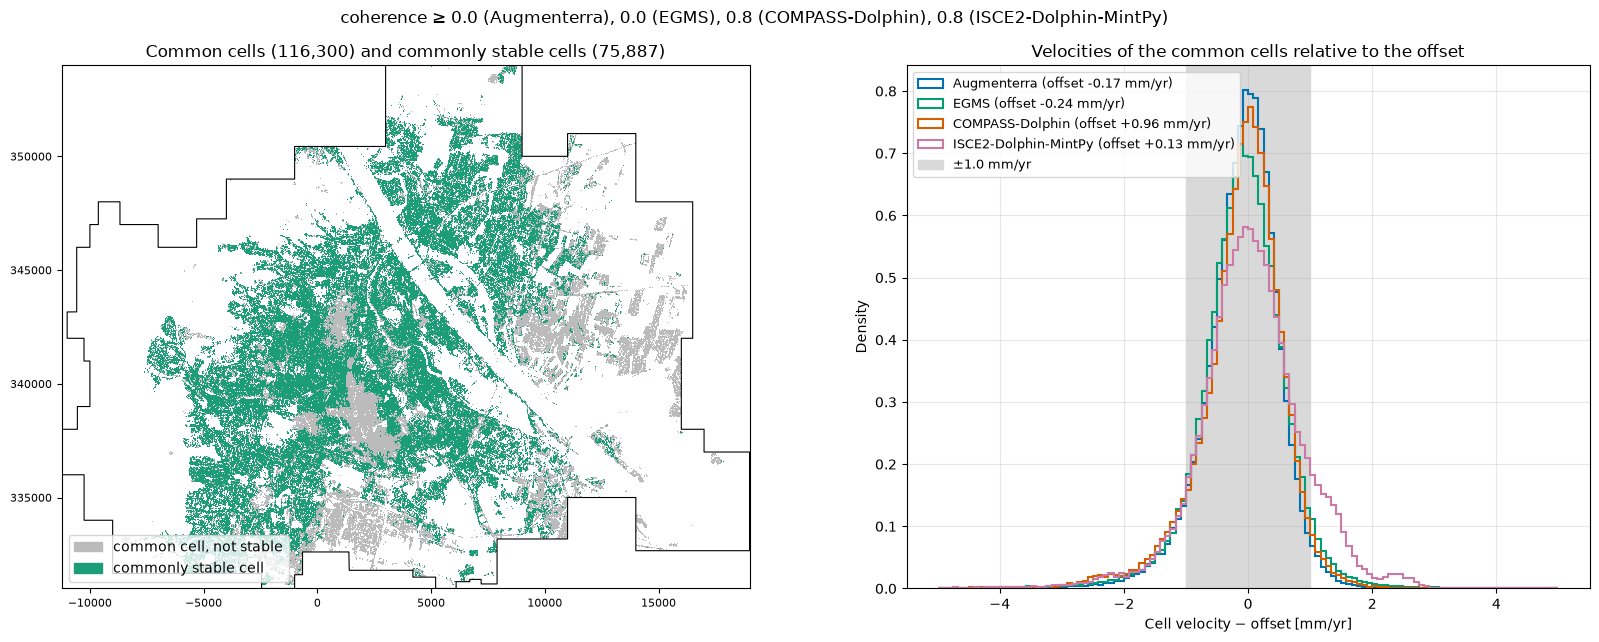

In [11]:
fig, (ax_map, ax_hist) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})

# 1 = common cell, 2 = commonly stable cell
cell_class = pd.Series(1.0, index=common_cells.index)
cell_class[stable_cells] = 2.0
class_cmap = ListedColormap(["#bbbbbb", "#1b9e77"])
ax_map.imshow(grid.to_image(cell_class), extent=grid.extent, cmap=class_cmap, vmin=0.5, vmax=2.5, interpolation="nearest")
ax_map.legend(handles=[Patch(color="#bbbbbb", label="common cell, not stable"),
                       Patch(color="#1b9e77", label="commonly stable cell")], loc="lower left")
style_map(ax_map, aoi_metric)
ax_map.set_title(f"Common cells ({len(common_cells):,}) and commonly stable cells ({len(stable_cells):,})")

bins = np.linspace(-5 * STABLE_TOL, 5 * STABLE_TOL, 121)
for name in common_cells:
    ax_hist.hist(common_cells[name] - offsets[name], bins=bins, density=True, histtype="step", lw=1.5,
                 color=SOURCES[name].color, label=f"{name} (offset {offsets[name]:+.2f} mm/yr)")
ax_hist.axvspan(-STABLE_TOL, STABLE_TOL, color="0.85", zorder=0, label=f"±{STABLE_TOL} mm/yr")
ax_hist.set_xlabel("Cell velocity − offset [mm/yr]")
ax_hist.set_ylabel("Density")
ax_hist.set_title("Velocities of the common cells relative to the offset")
ax_hist.grid(alpha=0.3)
ax_hist.legend(fontsize=9)

plt.suptitle(COH_INFO)
plt.tight_layout()
plt.show()

## 5. Pairwise comparison of cell velocities

Only cells where both datasets have at least `MIN_POINTS_PER_CELL` points are compared.
References come first in a pair, the own processings second (in the order of `OWN`).
The pairwise plots are laid out in rows of `PLOTS_PER_ROW` panels.

If `ALIGN_TO_STABLE` is True, the offsets of section 4 are subtracted (`comparisons`), otherwise the raw velocities
are used. The raw comparison is always kept as well (`comparisons_raw`) for the before/after metrics.

In [12]:
names = list(cell_stats)
pairs = [tuple(sorted(pair, key=lambda name: OWN.index(name) + 1 if name in OWN else 0))
         for pair in combinations(names, 2)]


def used_velocity(name):
    """Cell velocities of a dataset, only cells with enough points."""
    stats = cell_stats[name]
    return stats.loc[stats["count"] >= MIN_POINTS_PER_CELL, CELL_AGG]


def compare(a, b, aligned=ALIGN_TO_STABLE):
    """Cell velocities of two datasets, only cells where both have a value (index = cell id).

    aligned=True subtracts the offsets of section 4 from both datasets.
    """
    df = pd.concat({a: used_velocity(a), b: used_velocity(b)}, axis=1, join="inner").dropna()
    return df - VELOCITY_OFFSET[[a, b]] if aligned else df


comparisons = {(a, b): compare(a, b) for a, b in pairs}                     # used for all plots below
comparisons_raw = {(a, b): compare(a, b, aligned=False) for a, b in pairs}  # before alignment
print(ALIGN_INFO)
print("Pairs:", ", ".join(f"{b} vs {a}" for a, b in pairs))

aligned on 75,887 commonly stable cells
Pairs: EGMS vs Augmenterra, COMPASS-Dolphin vs Augmenterra, ISCE2-Dolphin-MintPy vs Augmenterra, COMPASS-Dolphin vs EGMS, ISCE2-Dolphin-MintPy vs EGMS, ISCE2-Dolphin-MintPy vs COMPASS-Dolphin


### 5.1 Metrics

`metrics.difference_metrics` (difference = second − first):
* **N**: comparable cells; **cells only in …**: cells with data in one dataset only, which cannot be compared
* **bias**: mean difference; **median diff.**: robust version of the bias
* **MAE / RMSE**: mean absolute / root mean square difference
* **std diff. / NMAD**: spread of the differences (classic / robust, NMAD ≈ std for normal data)
* **Pearson r / Spearman ρ**: linear / rank correlation of the cell velocities

Removing a constant offset only changes bias, median diff., MAE, RMSE and |diff| ≤ 2 mm/yr.
Spread (std, NMAD) and correlation stay the same, they describe the agreement independent of the reference.

In [13]:
def pair_metrics(df, a, b):
    """difference_metrics of datasets a and b plus the cells that only one of them has."""
    m = metrics.difference_metrics(df[a], df[b])
    return {"N": m.pop("N"),
            "cells only in first": len(used_velocity(a)) - len(df),
            "cells only in second": len(used_velocity(b)) - len(df), **m}


metrics_aligned = pd.DataFrame({f"{b} − {a}": pair_metrics(df, a, b) for (a, b), df in comparisons.items()})
metrics_raw = pd.DataFrame({f"{b} − {a}": pair_metrics(df, a, b) for (a, b), df in comparisons_raw.items()})

int_rows = ("N", "cells only in first", "cells only in second")
if ALIGN_TO_STABLE:
    # raw and aligned next to each other for every pair
    both = pd.concat({"raw": metrics_raw, "aligned": metrics_aligned}, axis=1).swaplevel(axis=1)
    show(both[[(pair, version) for pair in metrics_aligned.columns for version in ("raw", "aligned")]],
         decimals=2, int_labels=int_rows)
else:
    show(metrics_raw, decimals=2, int_labels=int_rows)

### 5.2 Density scatter plots

With hundreds of thousands of cells a normal scatter plot is one dark blob, so the plots show how many cells
fall into each hexagon (log colour scale). Dashed line: 1:1.

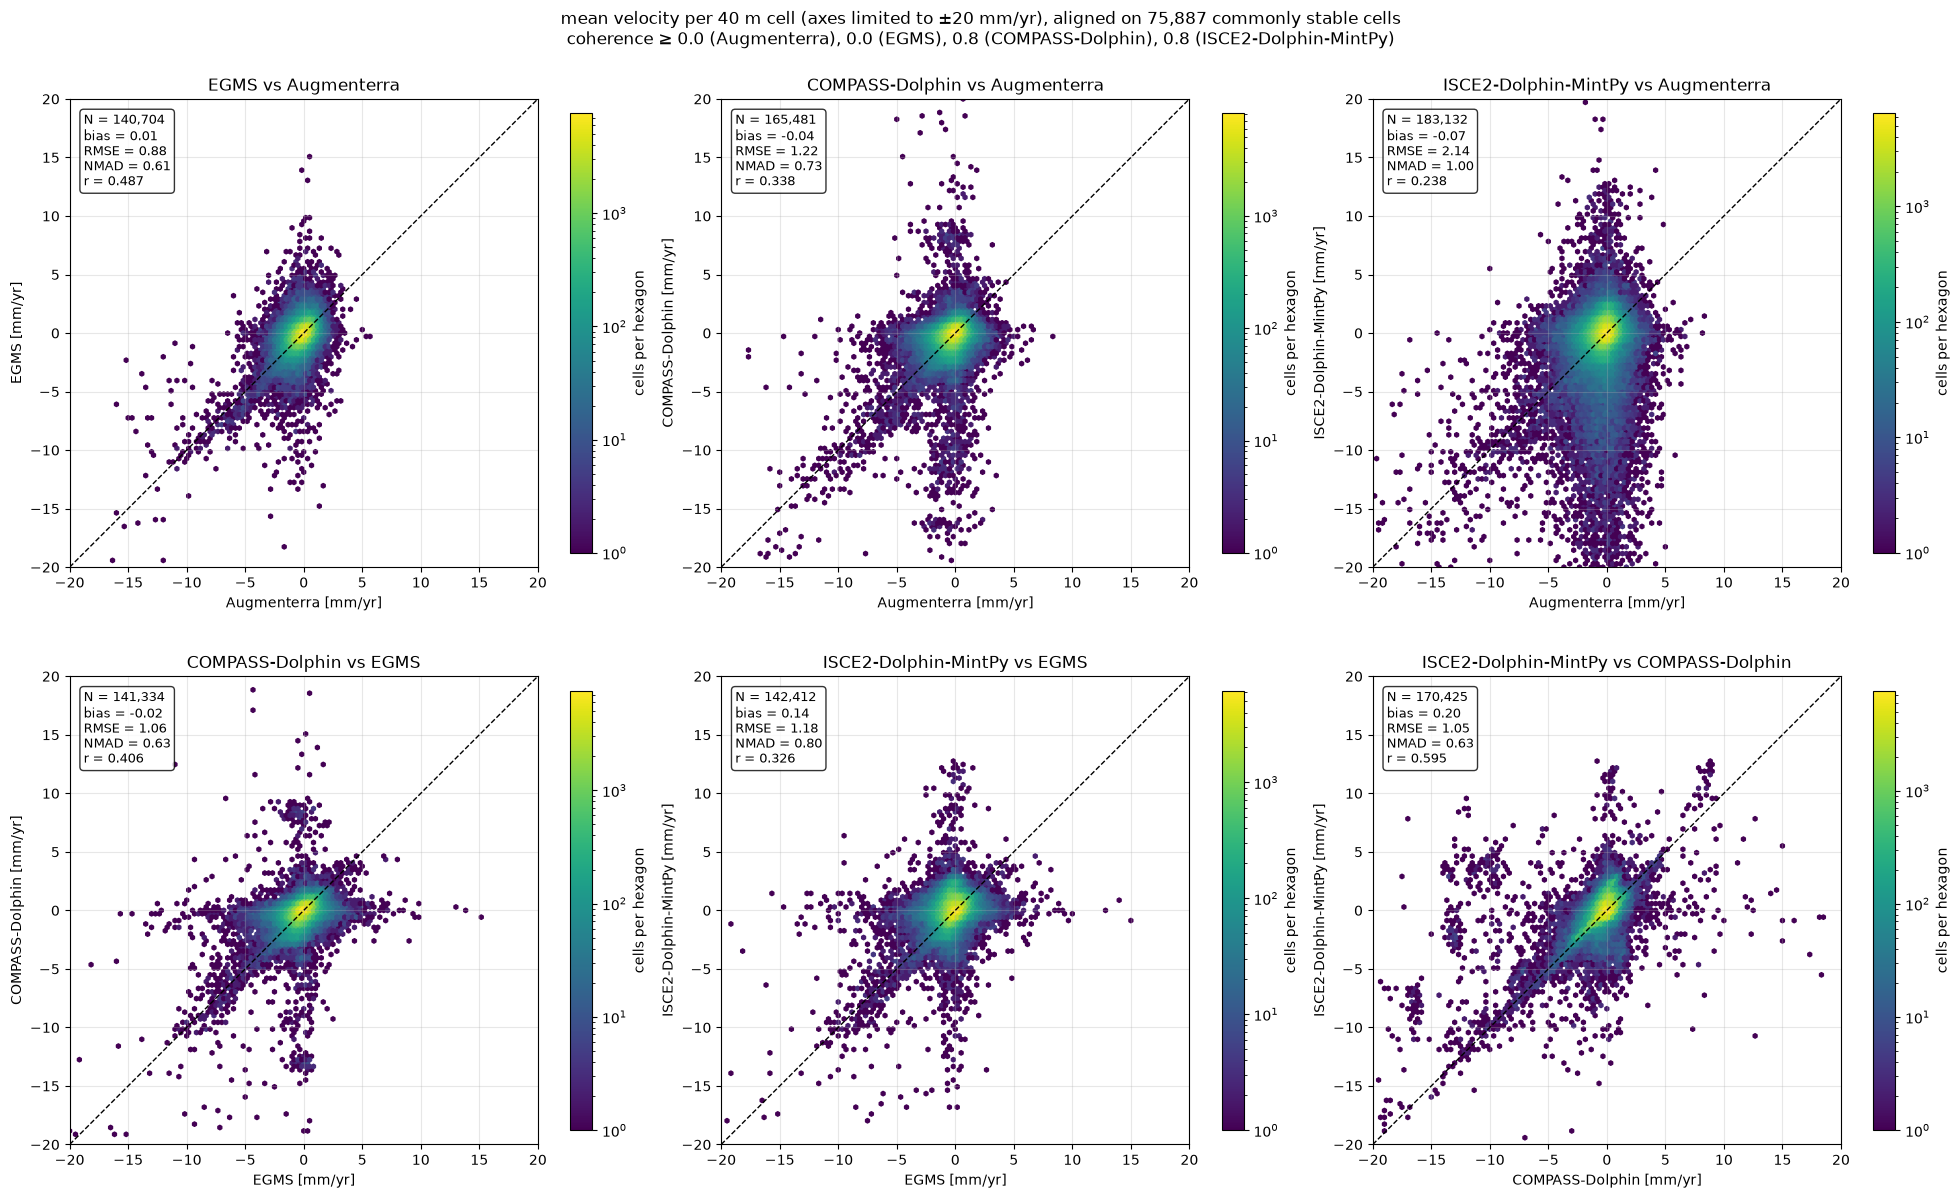

In [14]:
fig, axes = panel_axes(len(pairs), per_row=PLOTS_PER_ROW)

for ax, ((a, b), df) in zip(axes, comparisons.items()):
    hb = ax.hexbin(df[a], df[b], gridsize=120, extent=(-VEL_LIMIT, VEL_LIMIT, -VEL_LIMIT, VEL_LIMIT),
                   bins="log", mincnt=1, cmap="viridis")
    ax.plot([-VEL_LIMIT, VEL_LIMIT], [-VEL_LIMIT, VEL_LIMIT], "k--", lw=1)
    metrics_box(ax, metrics_aligned[f"{b} − {a}"])
    ax.set_xlim(-VEL_LIMIT, VEL_LIMIT)
    ax.set_ylim(-VEL_LIMIT, VEL_LIMIT)
    ax.set_aspect("equal")
    ax.set_xlabel(f"{a} [mm/yr]")
    ax.set_ylabel(f"{b} [mm/yr]")
    ax.set_title(f"{b} vs {a}")
    ax.grid(alpha=0.3)
    fig.colorbar(hb, ax=ax, shrink=0.8, label="cells per hexagon")

fig.suptitle(f"{CELL_AGG} velocity per {GRID_SIZE_M} m cell (axes limited to ±{VEL_LIMIT} mm/yr), "
             f"{ALIGN_INFO}\n{COH_INFO}")
plt.show()

### 5.3 Distribution of the differences

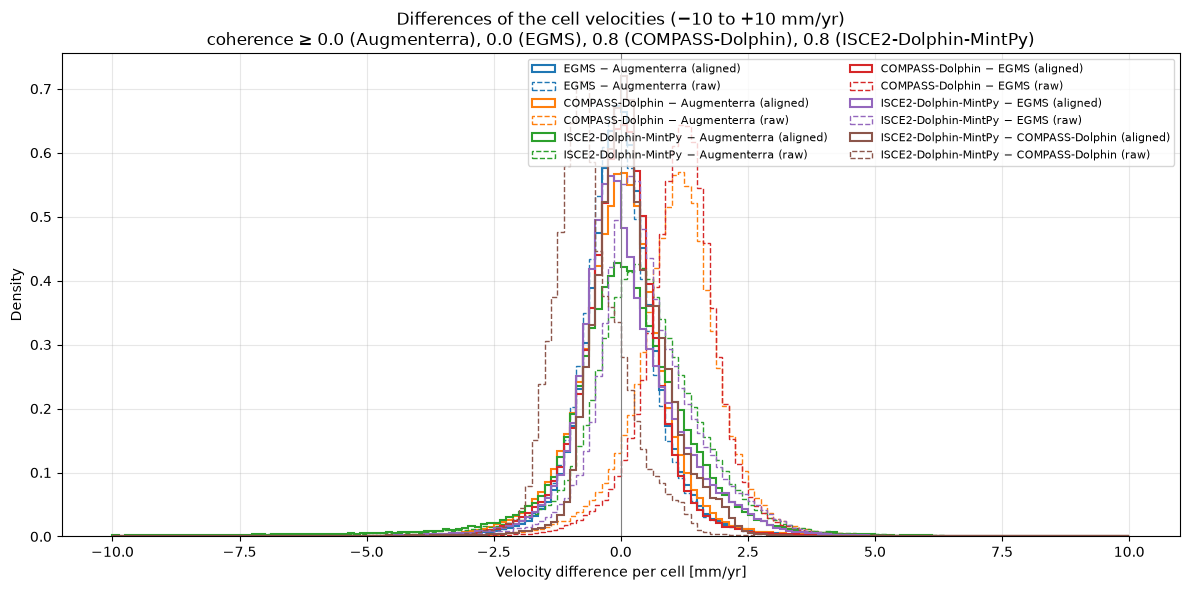

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))
bins = np.linspace(-DIFF_LIMIT, DIFF_LIMIT, 161)

for k, ((a, b), df) in enumerate(comparisons.items()):
    color = f"C{k}"
    ax.hist(df[b] - df[a], bins=bins, density=True, histtype="step", lw=1.5, color=color,
            label=f"{b} − {a}" + (" (aligned)" if ALIGN_TO_STABLE else ""))
    if ALIGN_TO_STABLE:   # dashed: before alignment
        raw = comparisons_raw[(a, b)]
        ax.hist(raw[b] - raw[a], bins=bins, density=True, histtype="step", lw=1, ls="--", color=color,
                label=f"{b} − {a} (raw)")

ax.axvline(0, color="0.5", lw=0.8)
ax.set_xlabel("Velocity difference per cell [mm/yr]")
ax.set_ylabel("Density")
ax.set_title(f"Differences of the cell velocities (−{DIFF_LIMIT} to +{DIFF_LIMIT} mm/yr)\n{COH_INFO}")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### 5.4 Difference maps

Difference second − first per cell. Red: the second dataset has lower (more negative) velocities.

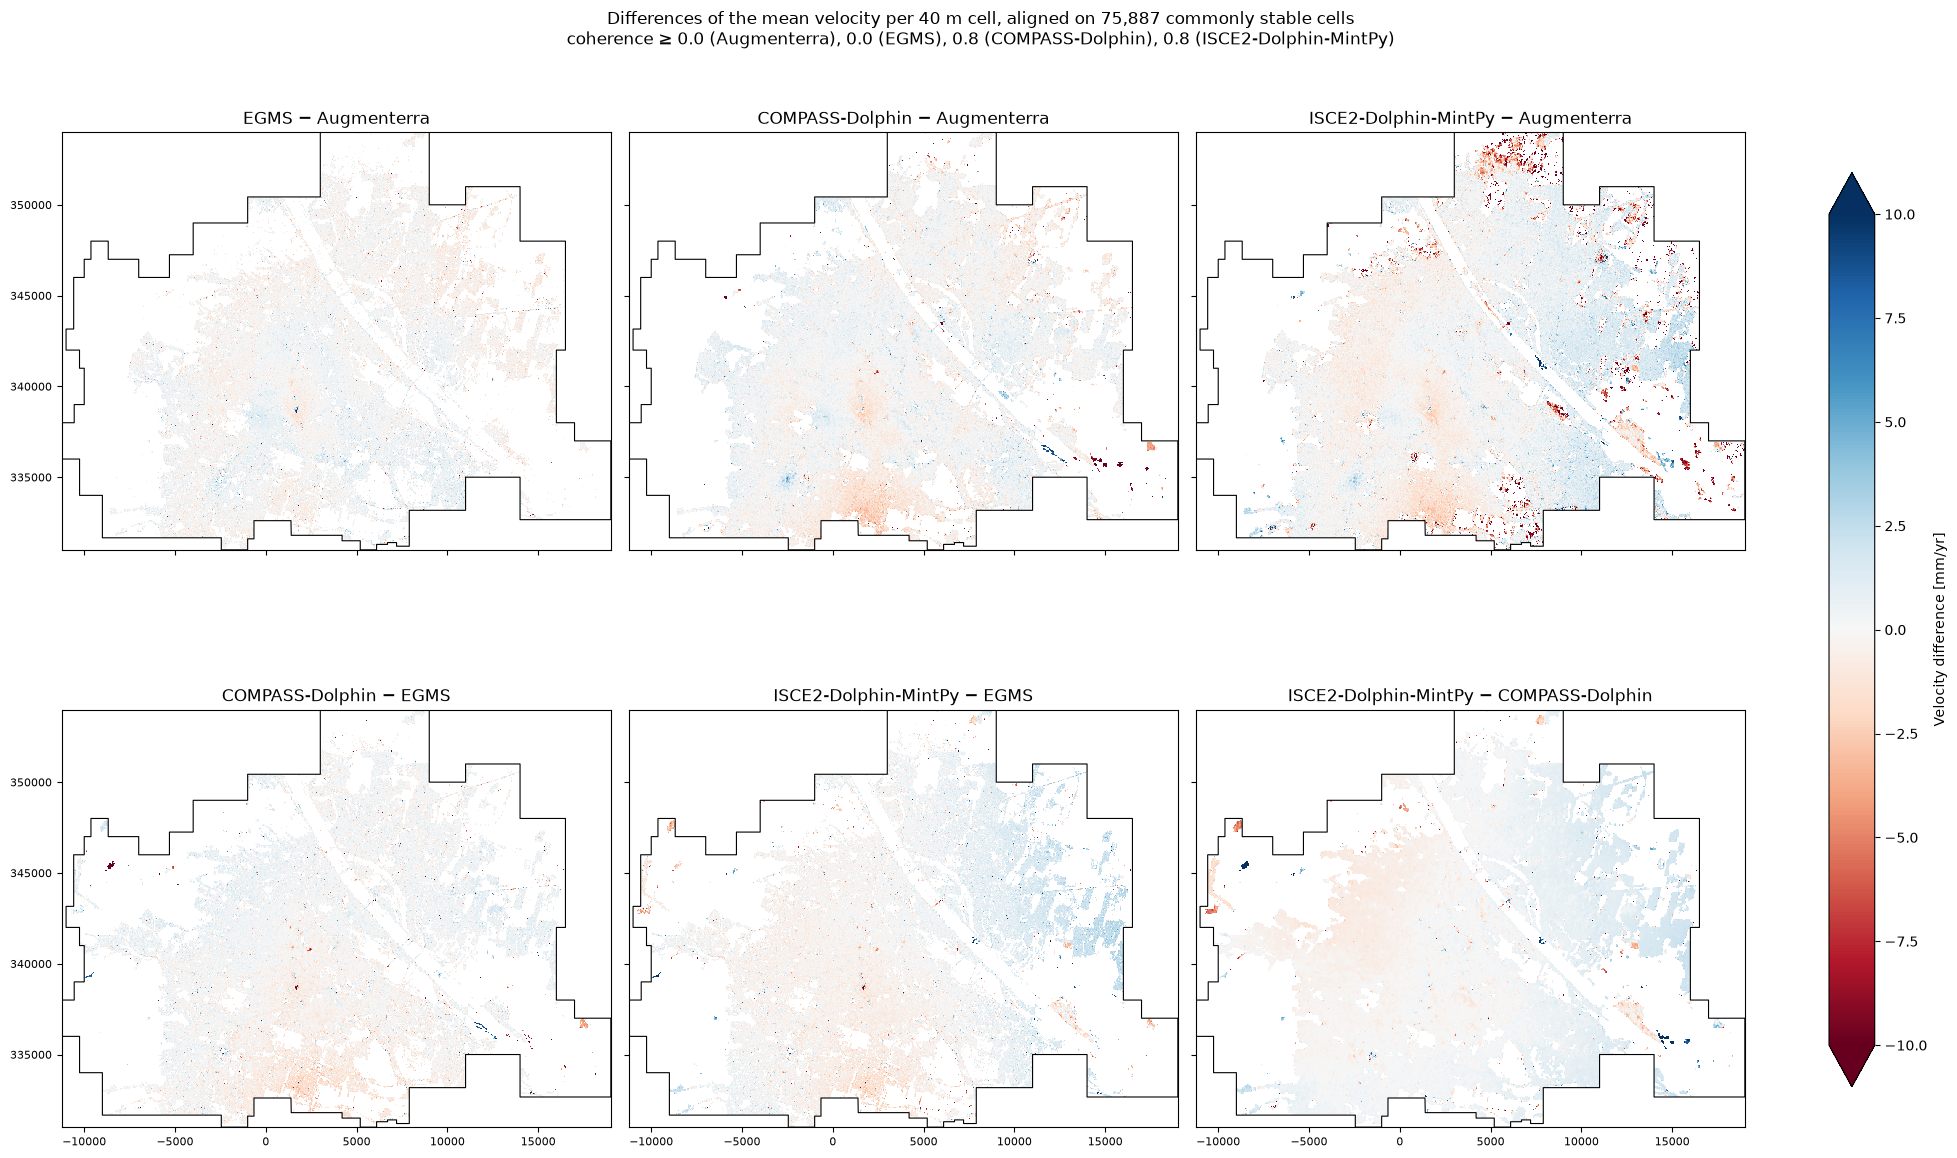

In [16]:
fig, axes = panel_axes(len(pairs), per_row=PLOTS_PER_ROW, sharex=True, sharey=True)
diff_norm = Normalize(-DIFF_LIMIT, DIFF_LIMIT)

for ax, ((a, b), df) in zip(axes, comparisons.items()):
    ax.imshow(grid.to_image(df[b] - df[a]), extent=grid.extent, cmap="RdBu", norm=diff_norm, interpolation="nearest")
    style_map(ax, aoi_metric)
    ax.set_title(f"{b} − {a}")

fig.colorbar(ScalarMappable(diff_norm, "RdBu"), ax=axes, extend="both", shrink=0.8,
             label="Velocity difference [mm/yr]")
fig.suptitle(f"Differences of the {CELL_AGG} velocity per {GRID_SIZE_M} m cell, {ALIGN_INFO}\n{COH_INFO}")
plt.show()

### 5.5 Agreement depending on the number of points per cell

Cells with only one or two points are noisy. This table shows how the agreement changes when only cells
with more points (in both datasets) are used.

In [17]:
BY_POINTS_COLUMNS = ["N", "median diff. [mm/yr]", "NMAD [mm/yr]", "RMSE [mm/yr]"]
tables = {}
for (a, b), df in comparisons.items():
    n_min = np.minimum(cell_stats[a].loc[df.index, "count"], cell_stats[b].loc[df.index, "count"])
    tables[f"{b} − {a}"] = metrics.difference_metrics_by(df[a], df[b], {f"≥ {k}": n_min >= k for k in [1, 2, 5, 10]})

by_points = pd.concat(tables)[BY_POINTS_COLUMNS]
by_points.index.names = ["pair", "points per cell"]
show(by_points, decimals=2, int_labels=("N",))

## Notes

Observation from an earlier run (own data `dolphin_postprocessed.parquet`, difference Augmenterra − own):
especially at the edges of the AOI the own processing showed lower velocities (mainly negative, i.e. subsidence),
whereas Augmenterra showed values around 0. Check whether this still holds with the current dataset
(note the reversed sign convention in this notebook: own − reference).

**Further ideas**
- Remove a remaining spatial trend (plane fit over the stable cells) in addition to the constant offset.
- Use an independent stable mask (e.g. GNSS-stable areas or EGMS L2b/L3) instead of the data-driven one.
- Compare the metrics for several coherence thresholds (`MIN_COHERENCE` in the configuration).